# Indonesia CO₂ Emissions Analysis Using Go

**Module:** 6FTC2177 – Next Generation Data Science  
**Assessment:** Assignment 2  
**Student Name:** Sahan Gamage  
**Student ID:** 2019HFIU  
**Country:** Indonesia  

## Introduction
This project analyses Indonesia’s annual national CO₂ emissions from 1970 to 2022 using Go. It explores changes over time and compares regression models for predicting annual emissions.

## Objectives
- Load, validate and clean the supplied dataset.
- Explore annual changes in CO₂ emissions.
- Compare a persistence baseline, a year-trend regression and a lag-1 regression.
- Evaluate predictions using MAE, RMSE and R².
- Present results using tables and graphs.

## Dataset
The supplied dataset contains 53 annual observations. Emissions are measured in Mt CO₂e and exclude land use, land-use change and forestry.

The national dataset does not contain district coordinates, temperature, population or health data. Real spatial matching and district comparisons require additional datasets.

## Tools
- Google Colab for running the project.
- Go for data processing, modelling and analysis.
- Ollama for AI assistance, with prompts and validation recorded in a separate log.
- ChatGPT for additional guidance and code review.

## 1. Environment Setup
The next cell installs Go and displays the installed version.

In [ ]:
!apt-get -qq update
!apt-get -qq install -y golang-go
!go version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package golang-1.22-src.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../golang-1.22-src_1.22.2-2ubuntu0.5_all.deb ...
Unpacking golang-1.22-src (1.22.2-2ubuntu0.5) ...
Selecting previously unselected package golang-1.22-go.
Preparing to unpack .../golang-1.22-go_1.22.2-2ubuntu0.5_amd64.deb ...
Unpacking golang-1.22-go (1.22.2-2ubuntu0.5) ...
Selecting previously unselected package golang-src.
Preparing to unpack .../golang-src_2%3a1.22~2build1_all.deb ...
Unpacking golang-src (2:1.22~2build1) ...
Selecting previously unselected package golang-go:amd64.
Preparing to unpack .../golang-go_2%3a1.22~2build1_amd64.deb ...
Unpacking golang-go:amd64 (2:1.22~2build1) ...
Setting up golang-1.22-src (1.22.2-2ubuntu0.5) ...
Setting

## 2. Create the Project Folder
Create a folder for the Go project and a data folder for the input CSV.

In [ ]:
import os

os.makedirs("/content/indonesia-co2/data", exist_ok=True)
os.chdir("/content/indonesia-co2")

print("Current folder:", os.getcwd())

Current folder: /content/indonesia-co2


## 3. Main Program
This file loads and validates the national CO₂ dataset, runs the analysis and saves the outputs.

In [ ]:
%%writefile main.go
package main

import (
	"encoding/csv"
	"errors"
	"flag"
	"fmt"
	"io"
	"math"
	"os"
	"path/filepath"
	"sort"
	"strconv"
	"strings"
)

type observation struct {
	year int
	co2  float64
}

type csvRow struct {
	line   int
	fields map[string]string
}

func main() {
	input := flag.String("input", "data/indonesia_co2.csv", "national CO2 CSV")
	output := flag.String("out", "outputs/national", "national output directory")
	trainEnd := flag.Int("train-end", 2014, "last training year")

	districtInput := flag.String("district-input", "", "directory containing standardized district CSVs")

	districtOut := flag.String("district-out", "outputs/district", "district output directory")
	radius := flag.Float64("match-km", 50, "maximum station-to-centroid distance")
	flag.Parse()

	if err := run(*input, *output, *trainEnd); err != nil {
		fail(err)
	}
	if *districtInput != "" {
		if err := runDistrict(*districtInput, *districtOut, *radius); err != nil {
			fail(err)
		}
		fmt.Println("District outputs:", *districtOut)
	}
}

func fail(err error) {
	fmt.Fprintln(os.Stderr, err)
	os.Exit(1)
}

func run(input, output string, trainEnd int) error {
	series, err := loadEmissions(input)
	if err != nil {
		return err
	}
	models, err := backtest(series, trainEnd)
	if err != nil {
		return err
	}
	if err := os.MkdirAll(output, 0755); err != nil {
		return err
	}
	if err := writeNational(output, series, trainEnd, models); err != nil {
		return err
	}
	fmt.Printf("Indonesia CO2 | %d observations | %d-%d\n", len(series), series[0].year, series[len(series)-1].year)
	fmt.Printf("Holdout | %d-%d | %d one-year-ahead predictions per model\n", trainEnd+1, series[len(series)-1].year, len(models[0].predictions))
	fmt.Printf("%-17s %9s %9s %9s\n", "Model", "MAE", "RMSE", "R²")
	for _, model := range models {
		s := evaluate(model.predictions)
		fmt.Printf("%-17s %9.2f %9.2f %9s\n", model.name, s.mae, s.rmse, rSquared(s, 3))
	}
	fmt.Println("MAE and RMSE in Mt CO2e")
	fmt.Println("Outputs:", output)
	return nil
}

func readCSV(path string, required ...string) ([]csvRow, error) {
	file, err := os.Open(path)
	if err != nil {
		return nil, err
	}
	defer file.Close()

	reader := csv.NewReader(file)
	headers, err := reader.Read()
	if err != nil {
		return nil, fmt.Errorf("%s: read header: %w", path, err)
	}
	seen := make(map[string]bool)
	for i, field := range headers {
		field = strings.TrimSpace(strings.TrimPrefix(field, "\uFEFF"))
		if field == "" || seen[field] {
			return nil, fmt.Errorf("%s: empty or duplicate header %q", path, field)
		}
		headers[i], seen[field] = field, true
	}
	for _, field := range required {
		if !seen[field] {
			return nil, fmt.Errorf("%s: missing column %q", path, field)
		}
	}
	var rows []csvRow
	for {
		values, err := reader.Read()
		if errors.Is(err, io.EOF) {
			break
		}
		if err != nil {
			return nil, fmt.Errorf("%s: %w", path, err)
		}
		line, _ := reader.FieldPos(0)
		fields := make(map[string]string, len(headers))
		for i, field := range headers {
			fields[field] = strings.TrimSpace(values[i])
		}
		rows = append(rows, csvRow{line, fields})
	}
	if len(rows) == 0 {
		return nil, fmt.Errorf("%s: missing data rows", path)
	}
	return rows, nil
}

func loadEmissions(path string) ([]observation, error) {
	rows, err := readCSV(path, "Country Code", "Indicator Code", "Year", "CO2_Mt_CO2e")
	if err != nil {
		return nil, err
	}
	byYear := make(map[int]float64)
	for _, row := range rows {
		f := row.fields
		if !strings.EqualFold(f["Country Code"], "IDN") || f["Indicator Code"] != "EN.GHG.CO2.MT.CE.AR5" {
			continue
		}
		year, validYear := parseYear(f["Year"])
		value, numeric := parseNumber(f["CO2_Mt_CO2e"])
		if !validYear || !numeric || value < 0 {
			return nil, fmt.Errorf("%s:%d: invalid year or emissions", path, row.line)
		}
		if previous, exists := byYear[year]; exists && previous != value {
			return nil, fmt.Errorf("%s:%d: conflicting values for %d", path, row.line, year)
		}
		byYear[year] = value
	}
	if len(byYear) == 0 {
		return nil, fmt.Errorf("%s: no records for the Indonesia CO2 indicator", path)
	}
	series := make([]observation, 0, len(byYear))
	for year, value := range byYear {
		series = append(series, observation{year, value})
	}
	sort.Slice(series, func(i, j int) bool { return series[i].year < series[j].year })
	for i := 1; i < len(series); i++ {
		if series[i].year != series[i-1].year+1 {
			return nil, fmt.Errorf("%s: missing annual observation after %d", path, series[i-1].year)
		}
	}
	return series, nil
}

func parseYear(raw string) (int, bool) {
	year, err := strconv.Atoi(raw)
	return year, err == nil && year >= 1800 && year <= 2200
}

func parseNumber(raw string) (float64, bool) {
	value, err := strconv.ParseFloat(raw, 64)
	return value, err == nil && !math.IsNaN(value) && !math.IsInf(value, 0)
}

func writeCSV(dir, name string, header []string, rows [][]string) error {
	return writeFile(dir, name, func(file *os.File) error {
		w := csv.NewWriter(file)
		if err := w.Write(header); err != nil {
			return err
		}
		return w.WriteAll(rows)
	})
}

func writeText(dir, name, content string) error {
	return writeFile(dir, name, func(file *os.File) error {
		_, err := file.WriteString(content)
		return err
	})
}

// Publish finished file contents through a rename in the same directory.
func writeFile(dir, name string, write func(*os.File) error) error {
	file, err := os.CreateTemp(dir, "."+name+"-*")
	if err != nil {
		return err
	}
	defer os.Remove(file.Name())
	writeErr := write(file)
	closeErr := file.Close()
	if writeErr != nil {
		return fmt.Errorf("%s: %w", name, writeErr)
	}
	if closeErr != nil {
		return fmt.Errorf("%s: %w", name, closeErr)
	}
	return os.Rename(file.Name(), filepath.Join(dir, name))
}

func fixed(v float64) string { return strconv.FormatFloat(v, 'f', 4, 64) }

Writing main.go


## 4. Regression Models and Evaluation
This file builds the prediction models, calculates evaluation metrics and exports the national analysis results.

In [ ]:
%%writefile analysis.go
package main

import (
	"fmt"
	"math"
	"path/filepath"
	"strconv"
)

type equation struct {
	intercept, slope float64
}

func (e equation) predict(x float64) float64 { return e.intercept + e.slope*x }

func fitOLS(x, y []float64) (equation, error) {
	if len(x) != len(y) || len(x) < 2 {
		return equation{}, fmt.Errorf("OLS requires at least two paired observations")
	}
	mx, my := mean(x), mean(y)
	var xx, xy float64
	for i, v := range x {
		xx += (v - mx) * (v - mx)
		xy += (v - mx) * (y[i] - my)
	}
	if xx == 0 {
		return equation{}, fmt.Errorf("OLS predictor has no variation")
	}
	slope := xy / xx
	return equation{my - slope*mx, slope}, nil
}

func mean(values []float64) float64 {
	var sum float64
	for _, value := range values {
		sum += value
	}
	return sum / float64(len(values))
}

type prediction struct {
	year              int
	actual, predicted float64
}

type model struct {
	name, feature string
	fit           equation
	predictions   []prediction
}

type scores struct{ mae, rmse, r2 float64 }

func backtest(series []observation, trainEnd int) ([]model, error) {
	split := 0
	for split < len(series) && series[split].year <= trainEnd {
		split++
	}
	if split < 4 || len(series)-split < 2 || series[split-1].year != trainEnd {
		return nil, fmt.Errorf("cutoff must leave at least four training years and two later years")
	}
	start := series[0].year
	var years, lags, targets []float64
	// Both regressions are fitted on the same target years.
	for i := 1; i < split; i++ {
		years = append(years, float64(series[i].year-start))
		lags = append(lags, series[i-1].co2)
		targets = append(targets, series[i].co2)
	}
	trend, err := fitOLS(years, targets)
	if err != nil {
		return nil, err
	}
	lag, err := fitOLS(lags, targets)
	if err != nil {
		return nil, err
	}
	models := []model{
		{name: "Persistence", feature: "prior_year_co2_mt_co2e", fit: equation{0, 1}},
		{name: "Year trend OLS", feature: fmt.Sprintf("year_minus_%d", start), fit: trend},
		{name: "Lag-1 OLS", feature: "prior_year_co2_mt_co2e", fit: lag},
	}
	for i := split; i < len(series); i++ {
		row := series[i]
		prior := series[i-1].co2
		features := []float64{prior, float64(row.year - start), prior}
		for j := range models {
			m := &models[j]
			m.predictions = append(m.predictions, prediction{row.year, row.co2, m.fit.predict(features[j])})
		}
	}
	return models, nil
}

func evaluate(rows []prediction) scores {
	n := float64(len(rows))
	var sum, absolute, ssResidual, ssTotal float64
	for _, row := range rows {
		sum += row.actual
	}
	avg := sum / n
	for _, row := range rows {
		residual, deviation := row.actual-row.predicted, row.actual-avg
		absolute += math.Abs(residual)
		ssResidual += residual * residual
		ssTotal += deviation * deviation
	}
	r2 := math.NaN()
	if ssTotal > 0 {
		r2 = 1 - ssResidual/ssTotal
	}
	return scores{absolute / n, math.Sqrt(ssResidual / n), r2}
}

func rSquared(s scores, digits int) string {
	if math.IsNaN(s.r2) {
		return ""
	}
	return strconv.FormatFloat(s.r2, 'f', digits, 64)
}

func writeNational(dir string, series []observation, trainEnd int, models []model) error {
	var cleaned, forecasts, metrics, coefficients [][]string
	var rise, fall float64
	var riseYear, fallYear int
	for i, row := range series {
		var deltaText, pct string
		if i > 0 {
			prev := series[i-1].co2
			delta := row.co2 - prev
			deltaText = fixed(delta)
			if prev > 0 {
				pct = fixed(100 * delta / prev)
			}
			if i == 1 || delta > rise {
				rise, riseYear = delta, row.year
			}
			if i == 1 || delta < fall {
				fall, fallYear = delta, row.year
			}
		}
		cleaned = append(cleaned, []string{"IDN", strconv.Itoa(row.year), fixed(row.co2), deltaText, pct})
	}
	best := models[0].name
	bestRMSE := math.Inf(1)
	for _, m := range models {
		s := evaluate(m.predictions)
		if s.rmse < bestRMSE {
			best, bestRMSE = m.name, s.rmse
		}
		metrics = append(metrics, []string{m.name, strconv.Itoa(len(m.predictions)), fixed(s.mae), fixed(s.rmse), rSquared(s, 4)})
		coefficients = append(coefficients, []string{m.name, m.feature, fixed(m.fit.intercept), fixed(m.fit.slope)})
		for _, p := range m.predictions {
			forecasts = append(forecasts, []string{m.name, strconv.Itoa(p.year), fixed(p.actual), fixed(p.predicted), fixed(p.actual - p.predicted)})
		}
	}
	for _, table := range []struct {
		name   string
		header []string
		rows   [][]string
	}{
		{"annual_co2_clean.csv", []string{"country_code", "year", "co2_mt_co2e", "yoy_change_mt_co2e", "yoy_change_pct"}, cleaned},
		{"model_metrics.csv", []string{"model", "holdout_years", "mae_mt_co2e", "rmse_mt_co2e", "r_squared"}, metrics},
		{"model_coefficients.csv", []string{"model", "predictor", "intercept", "slope"}, coefficients},
		{"holdout_predictions.csv", []string{"model", "year", "actual_mt_co2e", "predicted_mt_co2e", "actual_minus_prediction_mt_co2e"}, forecasts},
	} {
		if err := writeCSV(dir, table.name, table.header, table.rows); err != nil {
			return err
		}
	}
	first, last := series[0], series[len(series)-1]
	report := fmt.Sprintf(`# Indonesia’s national CO2 emissions

The supplied data contain %d consecutive years from %d to %d. The indicator (EN.GHG.CO2.MT.CE.AR5) measures national CO2 emissions excluding land use, land-use change and forestry, in Mt CO2e.

- Emissions rose from **%.4f Mt CO2e in %d** to **%.4f Mt CO2e in %d**. The net change was %+.4f Mt CO2e.
- The largest annual increase was **%+.4f Mt CO2e in %d**. The smallest annual change was **%+.4f Mt CO2e in %d**.

## Model performance

The OLS models used %d–%d target years. The holdout covered %d–%d. Lagged models use the previous observed year for each one-year-ahead prediction. Model coefficients remain fixed after training.

| Model | MAE (Mt CO2e) | RMSE (Mt CO2e) | R² |
|---|---:|---:|---:|
`, len(series), first.year, last.year, first.co2, first.year, last.co2, last.year, last.co2-first.co2, rise, riseYear, fall, fallYear, first.year+1, trainEnd, trainEnd+1, last.year)
	for _, m := range models {
		s := evaluate(m.predictions)
		r2 := rSquared(s, 3)
		if r2 == "" {
			r2 = "undefined"
		}
		report += fmt.Sprintf("| %s | %.2f | %.2f | %s |\n", m.name, s.mae, s.rmse, r2)
	}
	report += fmt.Sprintf(`
**%s** had the lowest RMSE (**%.2f Mt CO2e**) on this holdout. The fitted time trend was %.2f Mt CO2e per year. In the lag regression, an extra 1 Mt CO2e in the previous year increases the fitted next-year value by %.4f Mt CO2e. These are descriptive relationships, and the scores depend on a single holdout of %d years.

## Geographic and data coverage

The source reports one national total per year. District emissions, climate and health relationships require the lecturer’s district, coordinate, temperature, demographics and health datasets.
`, best, bestRMSE, models[1].fit.slope, models[2].fit.slope, len(models[0].predictions))
	if err := writeText(dir, "insights.md", report); err != nil {
		return err
	}
	return writePlots(filepath.Join(dir, "plots"), series, trainEnd, models)
}

Writing analysis.go


## 5. Optional District Data Processing
This file matches weather stations to district centres and joins temperature, population and health data by district and year. Real district analysis requires the additional input datasets.

In [ ]:
%%writefile district.go
package main

import (
	"fmt"
	"math"
	"os"
	"path/filepath"
	"sort"
	"strconv"
)

type point struct{ lat, lon float64 }
type district struct {
	id, name string
	center   point
}
type yearKey struct {
	id   string
	year int
}
type aggregate struct {
	count int
	sum   float64
}
type match struct {
	district string
	km       float64
	status   string
}

func coordinates(row csvRow) (point, bool) {
	lat, validLat := parseNumber(row.fields["latitude"])
	lon, validLon := parseNumber(row.fields["longitude"])
	return point{lat, lon}, validLat && validLon && math.Abs(lat) <= 90 && math.Abs(lon) <= 180
}

func haversine(from, to point) float64 {
	const rad = math.Pi / 180
	a, b := math.Sin((to.lat-from.lat)*rad/2), math.Sin((to.lon-from.lon)*rad/2)
	v := a*a + math.Cos(from.lat*rad)*math.Cos(to.lat*rad)*b*b
	return 2 * 6371.0088 * math.Asin(math.Sqrt(math.Min(1, math.Max(0, v))))
}

func nearest(station point, districts []district, radius float64) match {
	best := match{km: math.Inf(1), status: "outside_radius"}
	tied := false
	for _, d := range districts {
		km := haversine(station, d.center)
		if math.Abs(km-best.km) <= 1e-8 {
			tied = true
		} else if km < best.km {
			best.district, best.km, tied = d.id, km, false
		}
	}
	switch {
	case best.km > radius:
		best.district = ""
	case tied:
		best.district, best.status = "", "ambiguous_tie"
	default:
		best.status = "matched"
	}
	return best
}

func runDistrict(input, output string, radius float64) error {
	if radius <= 0 || math.IsNaN(radius) || math.IsInf(radius, 0) {
		return fmt.Errorf("match radius must be finite and positive")
	}
	rows, err := readCSV(filepath.Join(input, "districts.csv"), "district_id", "district_name", "latitude", "longitude")
	if err != nil {
		return err
	}
	var districts []district
	names := make(map[string]string)
	for _, row := range rows {
		id, name := row.fields["district_id"], row.fields["district_name"]
		p, valid := coordinates(row)
		if id == "" || name == "" || !valid || names[id] != "" {
			return fmt.Errorf("districts.csv:%d: invalid or duplicate district", row.line)
		}
		names[id] = name
		districts = append(districts, district{id, name, p})
	}
	pop, err := loadDistrictValues(input, "demographics.csv", "population", names)
	if err != nil {
		return err
	}
	health, err := loadDistrictValues(input, "health.csv", "health_rate", names)
	if err != nil {
		return err
	}
	temps, audit, err := matchWeather(input, districts, radius)
	if err != nil {
		return err
	}

	keys := make(map[yearKey]bool)
	for k := range pop {
		keys[k] = true
	}
	for k := range health {
		keys[k] = true
	}
	for k := range temps {
		keys[k] = true
	}
	ordered := make([]yearKey, 0, len(keys))
	for k := range keys {
		ordered = append(ordered, k)
	}
	sort.Slice(ordered, func(i, j int) bool {
		if ordered[i].id == ordered[j].id {
			return ordered[i].year < ordered[j].year
		}
		return ordered[i].id < ordered[j].id
	})
	type districtStats struct {
		allTemps, allHealth, pairedTemps, pairedHealth []float64
	}
	stats := make(map[string]*districtStats)
	var panel, summary [][]string
	for _, k := range ordered {
		s := stats[k.id]
		if s == nil {
			s = &districtStats{}
			stats[k.id] = s
		}
		w := temps[k]
		h, hasHealth := health[k]
		var tempText, popText, healthText string
		if w.count > 0 {
			value := w.sum / float64(w.count)
			tempText = fixed(value)
			s.allTemps = append(s.allTemps, value)
			if hasHealth {
				s.pairedTemps = append(s.pairedTemps, value)
				s.pairedHealth = append(s.pairedHealth, h)
			}
		}
		if v, ok := pop[k]; ok {
			popText = strconv.FormatFloat(v, 'f', 0, 64)
		}
		if hasHealth {
			healthText = fixed(h)
			s.allHealth = append(s.allHealth, h)
		}
		panel = append(panel, []string{k.id, names[k.id], strconv.Itoa(k.year), tempText, strconv.Itoa(w.count), popText, healthText})
	}
	sort.Slice(districts, func(i, j int) bool { return districts[i].id < districts[j].id })
	for _, d := range districts {
		s := stats[d.id]
		if s == nil {
			s = &districtStats{}
		}
		summary = append(summary, []string{d.id, d.name, optionalMean(s.allTemps), optionalMean(s.allHealth),
			strconv.Itoa(len(s.pairedTemps)), pearson(s.pairedTemps, s.pairedHealth)})
	}

	if err := os.MkdirAll(output, 0755); err != nil {
		return err
	}
	if err := writeCSV(output, "station_matches.csv", []string{"station_id", "latitude", "longitude", "district_id", "nearest_km", "status"}, audit); err != nil {
		return err
	}
	if err := writeCSV(output, "district_year.csv", []string{"district_id", "district_name", "year", "mean_temp_c", "station_count", "population", "health_rate"}, panel); err != nil {
		return err
	}
	return writeCSV(output, "district_summary.csv", []string{"district_id", "district_name", "mean_temp_c", "mean_health_rate", "paired_years", "temp_health_pearson_r"}, summary)
}

func loadDistrictValues(dir, file, field string, names map[string]string) (map[yearKey]float64, error) {
	rows, err := readCSV(filepath.Join(dir, file), "district_id", "year", field)
	if err != nil {
		return nil, err
	}
	values := make(map[yearKey]float64)
	for _, row := range rows {
		id := row.fields["district_id"]
		year, validYear := parseYear(row.fields["year"])
		if names[id] == "" || !validYear {
			return nil, fmt.Errorf("%s:%d: invalid district or year", file, row.line)
		}
		raw := row.fields[field]
		if raw == "" || raw == "NA" {
			continue
		}
		v, valid := parseNumber(raw)
		if !valid || v < 0 || (field == "population" && math.Trunc(v) != v) {
			return nil, fmt.Errorf("%s:%d: invalid %s", file, row.line, field)
		}
		k := yearKey{id, year}
		if old, exists := values[k]; exists && old != v {
			return nil, fmt.Errorf("%s:%d: conflicting %s values for district and year", file, row.line, field)
		}
		values[k] = v
	}
	return values, nil
}

func matchWeather(dir string, districts []district, radius float64) (map[yearKey]aggregate, [][]string, error) {
	rows, err := readCSV(filepath.Join(dir, "temperature.csv"), "station_id", "year", "latitude", "longitude", "mean_temp_c")
	if err != nil {
		return nil, nil, err
	}
	points := make(map[string]point)
	matches := make(map[string]match)
	stationYears := make(map[yearKey]float64)
	weather := make(map[yearKey]aggregate)
	var audit [][]string
	for _, row := range rows {
		station := row.fields["station_id"]
		p, validPoint := coordinates(row)
		year, validYear := parseYear(row.fields["year"])
		if station == "" || !validPoint || !validYear {
			return nil, nil, fmt.Errorf("temperature.csv:%d: invalid station, coordinate or year", row.line)
		}
		old, exists := points[station]
		if exists && old != p {
			return nil, nil, fmt.Errorf("temperature.csv:%d: inconsistent coordinates for station", row.line)
		}
		if !exists {
			m := nearest(p, districts, radius)
			points[station], matches[station] = p, m
			audit = append(audit, []string{station, fixed(p.lat), fixed(p.lon), m.district, fixed(m.km), m.status})
		}
		raw := row.fields["mean_temp_c"]
		if raw == "" || raw == "NA" {
			continue
		}
		v, valid := parseNumber(raw)
		if !valid || v < -90 || v > 65 {
			return nil, nil, fmt.Errorf("temperature.csv:%d: invalid annual temperature", row.line)
		}
		k := yearKey{station, year}
		if old, exists := stationYears[k]; exists {
			if old != v {
				return nil, nil, fmt.Errorf("temperature.csv:%d: conflicting station-year values", row.line)
			}
			continue
		}
		stationYears[k] = v
		if id := matches[station].district; id != "" {
			key := yearKey{id, year}
			existing := weather[key]
			existing.count++
			existing.sum += v
			weather[key] = existing
		}
	}
	sort.Slice(audit, func(i, j int) bool { return audit[i][0] < audit[j][0] })
	return weather, audit, nil
}

func optionalMean(values []float64) string {
	if len(values) == 0 {
		return ""
	}
	return fixed(mean(values))
}

func pearson(x, y []float64) string {
	if len(x) < 3 {
		return ""
	}
	mx, my := mean(x), mean(y)
	var xx, yy, xy float64
	for i, v := range x {
		dx, dy := v-mx, y[i]-my
		xx += dx * dx
		yy += dy * dy
		xy += dx * dy
	}
	if xx == 0 || yy == 0 {
		return ""
	}
	return fixed(xy / math.Sqrt(xx*yy))
}

Writing district.go


## 6. Visualise the Results
This file generates SVG graphs showing annual CO₂ emissions and holdout predictions.

In [ ]:
%%writefile plots.go
package main

import (
	"fmt"
	"html"
	"math"
	"os"
	"strings"
)

type curve struct {
	label, color string
	points       []observation
}

func writePlots(dir string, data []observation, trainEnd int, models []model) error {
	if err := os.MkdirAll(dir, 0755); err != nil {
		return err
	}
	all := []curve{{"Observed emissions", "#087D72", data}}
	holdout := []curve{{"Observed", "#162D41", data[len(data)-len(models[0].predictions):]}}
	colors := []string{"#087D72", "#B45509", "#7344A3"}
	for i, m := range models {
		points := make([]observation, 0, len(m.predictions))
		for _, p := range m.predictions {
			points = append(points, observation{p.year, p.predicted})
		}
		holdout = append(holdout, curve{m.name, colors[i], points})
	}
	if err := writeText(dir, "annual_emissions.svg", plot("Indonesia’s annual CO2 emissions", "National total excluding land use, land-use change and forestry", all, trainEnd)); err != nil {
		return err
	}
	return writeText(dir, "holdout_predictions.svg", plot("One-year-ahead CO2 predictions", "Chronological holdout with fixed regression coefficients", holdout, 0))
}

func plot(title, subtitle string, curves []curve, cutoff int) string {
	years := curves[0].points
	start, end := years[0].year, years[len(years)-1].year
	lo, hi := 0.0, 0.0
	if len(curves) > 1 {
		lo, hi = years[0].co2, years[0].co2
	}
	for _, c := range curves {
		for _, p := range c.points {
			lo, hi = math.Min(lo, p.co2), math.Max(hi, p.co2)
		}
	}
	step := math.Max(50, math.Ceil((hi-lo)/350)*50)
	lo = step * math.Floor(lo/step)
	hi = math.Max(lo+step, step*math.Ceil(hi/step))
	x := func(year int) float64 { return 94 + 904*float64(year-start)/float64(end-start) }
	y := func(v float64) float64 { return 435 - 306*(v-lo)/(hi-lo) }
	var b strings.Builder
	fmt.Fprintf(&b, "<svg xmlns=\"http://www.w3.org/2000/svg\" viewBox=\"0 0 1056 536\" width=\"1056\" height=\"536\" role=\"img\"><title>%s</title>\n", html.EscapeString(title))
	b.WriteString("<rect width=\"1056\" height=\"536\" fill=\"#FAFAF7\"/><g font-family=\"Arial,sans-serif\" fill=\"#162D41\">\n")
	fmt.Fprintf(&b, "<text x=\"45\" y=\"50\" font-size=\"31\" font-weight=\"700\">%s</text><text x=\"45\" y=\"80\" font-size=\"17\">%s</text><text x=\"45\" y=\"112\" font-size=\"14\">Mt CO2e</text>\n", html.EscapeString(title), html.EscapeString(subtitle))
	for v := lo; v <= hi; v += step {
		fmt.Fprintf(&b, "<path d=\"M94 %.2fH998\" stroke=\"#D7E1DE\"/><text x=\"82\" y=\"%.2f\" text-anchor=\"end\" font-size=\"14\">%.0f</text>\n", y(v), y(v)+4, v)
	}
	label := func(year int) {
		fmt.Fprintf(&b, "<text x=\"%.2f\" y=\"460\" font-size=\"14\" text-anchor=\"middle\">%d</text>\n", x(year), year)
	}
	stride := 1
	if end-start > 12 {
		stride = 10 * int(math.Ceil(float64(end-start)/60))
	}
	for year := start; year <= end-1; year += stride {
		if end-year > stride/2 {
			label(year)
		}
	}
	label(end)
	if cutoff > start && cutoff < end {
		divider := (x(cutoff) + x(cutoff+1)) / 2
		anchor, offset := "start", 8.0
		if divider > 820 {
			anchor, offset = "end", -8
		}
		fmt.Fprintf(&b, "<path d=\"M%.2f 129V435\" stroke=\"#728087\" stroke-dasharray=\"4 5\"/><text x=\"%.2f\" y=\"150\" text-anchor=\"%s\" font-size=\"14\">Holdout begins %d</text>\n", divider, divider+offset, anchor, cutoff+1)
	}
	for i, c := range curves {
		dash := ""
		if i > 0 {
			dash = " stroke-dasharray=\"8 5\""
		}
		fmt.Fprintf(&b, "<polyline fill=\"none\" stroke=\"%s\" stroke-width=\"3\"%s points=\"", c.color, dash)
		for _, p := range c.points {
			fmt.Fprintf(&b, "%.2f,%.2f ", x(p.year), y(p.co2))
		}
		b.WriteString("\"/>\n")
		for _, p := range c.points {
			fmt.Fprintf(&b, "<circle cx=\"%.2f\" cy=\"%.2f\" r=\"3\" fill=\"%s\"/>\n", x(p.year), y(p.co2), c.color)
		}
		pos := 94 + i*223
		fmt.Fprintf(&b, "<path d=\"M%d 497h27\" stroke=\"%s\" stroke-width=\"3\"%s/><text x=\"%d\" y=\"502\" font-size=\"15\">%s</text>\n", pos, c.color, dash, pos+35, html.EscapeString(c.label))
	}
	b.WriteString("</g></svg>\n")
	return b.String()
}

Writing plots.go


## 7. Code Validation Tests
These tests check OLS calculations, national data coverage, holdout predictions, leakage prevention and district matching. District tests use synthetic sample data.

In [ ]:
%%writefile main_test.go
package main

import (
	"math"
	"os"
	"path/filepath"
	"testing"
)

func TestOLS(t *testing.T) {
	m, err := fitOLS([]float64{1, 2, 3}, []float64{5, 7, 9})
	if err != nil || m != (equation{3, 2}) || m.predict(4) != 11 {
		t.Fatalf("expected 3+2x, got %+v, err=%v", m, err)
	}
}

func TestIndonesiaHoldout(t *testing.T) {
	data, err := loadEmissions("data/indonesia_co2.csv")
	if err != nil {
		t.Fatal(err)
	}
	if len(data) != 53 || data[0] != (observation{1970, 31.1237}) || data[52] != (observation{2022, 722.6996}) {
		t.Fatal("supplied data endpoints or row count changed")
	}
	models, err := backtest(data, 2014)
	if err != nil {
		t.Fatal(err)
	}
	p := models[0].predictions
	if len(p) != 8 || p[0].predicted != 505.0762 || p[7].predicted != 622.6868 {
		t.Fatal("persistence must use each actual prior year")
	}
	for i, want := range []float64{48.3250, 82.9646, 40.8707} {
		if got := evaluate(models[i].predictions).rmse; math.Abs(got-want) > .012 {
			t.Fatalf("%s RMSE = %.5f", models[i].name, got)
		}
	}
	changed := append([]observation(nil), data...)
	changed[45].co2 += 10
	recalculated, err := backtest(changed, 2014)
	if err != nil {
		t.Fatal(err)
	}
	if recalculated[2].fit != models[2].fit || recalculated[2].predictions[0].predicted != models[2].predictions[0].predicted {
		t.Fatal("the current holdout target leaked into model fitting or prediction")
	}
}

func TestDistrictMatchingAndJoin(t *testing.T) {
	in, out := t.TempDir(), t.TempDir()
	for name, content := range map[string]string{
		"districts.csv":    "district_id,district_name,latitude,longitude\n01,Alpha,0,0\n02,Beta,0,2\n",
		"temperature.csv":  "station_id,year,latitude,longitude,mean_temp_c\ns1,2020,0,0.1,20\ns1,2020,0,0.1,20\ns2,2020,0,0.2,24\ns3,2020,0,1,10\ns4,2020,0,5,18\ns1,2021,0,0.1,21\n",
		"demographics.csv": "district_id,year,population\n01,2020,100\n02,2020,200\n",
		"health.csv":       "district_id,year,health_rate\n01,2020,3\n01,2021,NA\n02,2020,5\n",
	} {
		if err := os.WriteFile(filepath.Join(in, name), []byte(content), 0600); err != nil {
			t.Fatal(err)
		}
	}
	if err := runDistrict(in, out, 150); err != nil {
		t.Fatal(err)
	}
	rows, err := readCSV(filepath.Join(out, "district_year.csv"), "mean_temp_c", "station_count")
	if err != nil {
		t.Fatal(err)
	}
	if len(rows) != 3 || rows[0].fields["mean_temp_c"] != "22.0000" || rows[0].fields["station_count"] != "2" || rows[1].fields["health_rate"] != "" || rows[2].fields["mean_temp_c"] != "" {
		t.Fatalf("unexpected join: %+v", rows)
	}
	matches, err := readCSV(filepath.Join(out, "station_matches.csv"), "status")
	if err != nil {
		t.Fatal(err)
	}
	if len(matches) != 4 || matches[2].fields["status"] != "ambiguous_tie" || matches[3].fields["status"] != "outside_radius" {
		t.Fatalf("unexpected audit: %+v", matches)
	}
	if d := haversine(point{0, 0}, point{0, 1}); math.Abs(d-111.19508) > .001 {
		t.Fatalf("unexpected distance %.6f", d)
	}
}

Writing main_test.go


## 8. Go Module Configuration
This file defines the project module name and minimum Go version.

In [8]:
%%writefile go.mod
module indonesia-emissions

go 1.20

Writing go.mod


## 9. Project Documentation
The README explains the dataset, project files, model evaluation and optional district pipeline.

In [9]:
%%writefile README.md
# Indonesia CO2 emissions analysis

This Go project analyses the supplied 1970–2022 national CO2 series for Indonesia (IDN, indicator EN.GHG.CO2.MT.CE.AR5). The source values are in Mt CO2e and exclude land use, land-use change and forestry.

## Project files

| Path | Contents |
|---|---|
| `data/indonesia_co2.csv` | The 53 source observations supplied with the assignment |
| `main.go`, `analysis.go`, `plots.go` | CSV validation, modelling, evaluation and SVG generation |
| `district.go` | Coordinate matching and annual district summaries |
| `main_test.go` | Checks for OLS, data coverage, leakage and district matching |
| `outputs/national/` | Cleaned observations, holdout predictions, coefficients, metrics, insights and plots |
| `screenshots/` | VS Code execution and displayed outputs |

The project uses Go 1.20 or newer and the standard library. From the project directory, `go run .` regenerates the national outputs. `go test -v ./...` runs the tests. The program accepts `-train-end` for a different chronological split.

The national loader selects the specified country and indicator, trims field whitespace, collapses identical duplicate years and rejects conflicting records, invalid values and year gaps. Annual change is computed against the previous observed year. An undefined percentage is left blank.

The default run uses 1971–2014 target years for both regressions, with 1970 supplying the initial lag. The holdout is 2015–2022. The predictor for lag-based models is the latest available observed annual total. Previous holdout observations enter only as lags after their year, and the fitted coefficients stay fixed. The program compares these predictions against observed national emissions using MAE, RMSE and R².

## District data and coverage

The supplied data has national coverage. The district code was verified with synthetic test fixtures. Real spatial matches and district summaries require the lecturer’s companion datasets and conversion to the schemas below. District CO2 estimates would also need observed district-level CO2 targets. The national total is kept at its original geographic level.

| File | Required columns |
|---|---|
| `districts.csv` | district_id, district_name, latitude, longitude |
| `temperature.csv` | station_id, year, latitude, longitude, mean_temp_c |
| `demographics.csv` | district_id, year, population |
| `health.csv` | district_id, year, health_rate |

The `-district-input` flag accepts a directory containing those normalized CSV files. Locations use WGS 84 decimal degrees. Station means represent a calendar year. Health observations must use one consistently defined rate and unit across districts and years.

The district pipeline assigns each station to the nearest district centroid by Haversine distance, using a configurable radius that defaults to 50 km. Equidistant stations and stations outside the radius are recorded in the match audit. Centroid proximity can disagree with administrative boundaries. Within each district-year, station means receive equal weight, and missing values are preserved as blank fields in the panel. The summary gives means for the available years and a descriptive Pearson correlation for matched temperature and health observations with at least three paired years and variation in both measures.

Writing README.md


## 10. Upload the Dataset
Upload the supplied Indonesia CO₂ CSV. The original data are saved without modification.

In [10]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload only the Indonesia CO2 CSV file.")

name, content = next(iter(uploaded.items()))

if not name.lower().endswith(".csv"):
    raise ValueError("Please select a CSV file.")

target = Path("/content/indonesia-co2/data/indonesia_co2.csv")
target.parent.mkdir(parents=True, exist_ok=True)
target.write_bytes(content)

print("Saved:", target)

Saving NGDS_CO2_Indonesia.csv to NGDS_CO2_Indonesia.csv
Saved: /content/indonesia-co2/data/indonesia_co2.csv


## 11. Run the Validation Tests
Run the automated tests to check the model calculations, holdout predictions and district matching logic.

In [11]:
%cd /content/indonesia-co2
!go test -v ./...

/content
=== RUN   TestOLS
--- PASS: TestOLS (0.00s)
=== RUN   TestIndonesiaHoldout
--- PASS: TestIndonesiaHoldout (0.00s)
=== RUN   TestDistrictMatchingAndJoin
--- PASS: TestDistrictMatchingAndJoin (0.00s)
PASS
ok  	indonesia-emissions	0.005s


## 12. Run the National CO₂ Analysis
Run the Go program to generate cleaned data, predictions, evaluation metrics, insights and SVG graphs.

In [12]:
%cd /content/indonesia-co2
!go run .

/content
Indonesia CO2 | 53 observations | 1970-2022
Holdout | 2015-2022 | 8 one-year-ahead predictions per model
Model                   MAE      RMSE        R²
Persistence           38.85     48.33     0.493
Year trend OLS        69.54     82.96    -0.494
Lag-1 OLS             32.28     40.87     0.637
MAE and RMSE in Mt CO2e
Outputs: outputs/national


## 13. Display the Graphs
The first graph shows annual national CO₂ emissions. The second compares observed emissions with the models’ one-year-ahead predictions during 2015–2022.

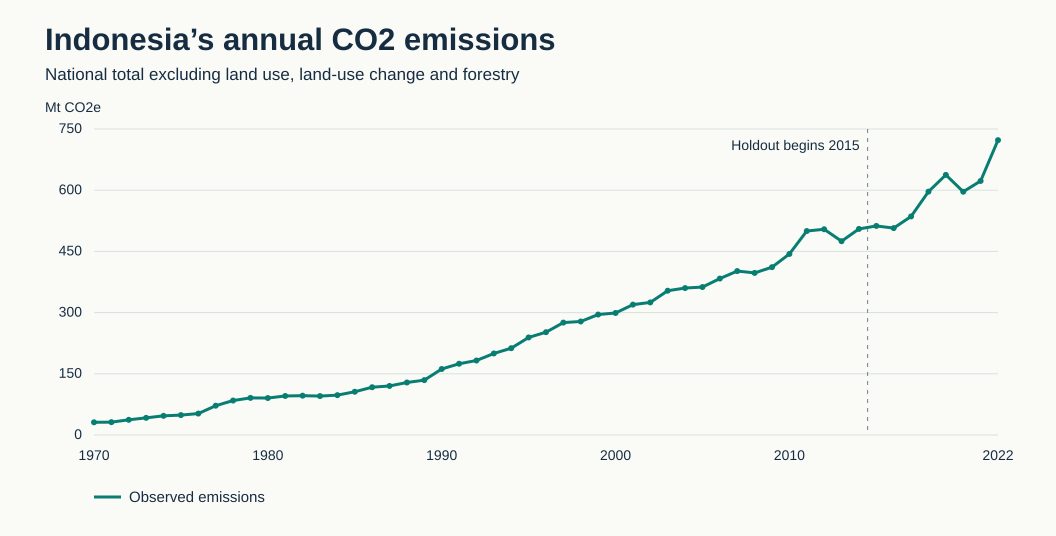

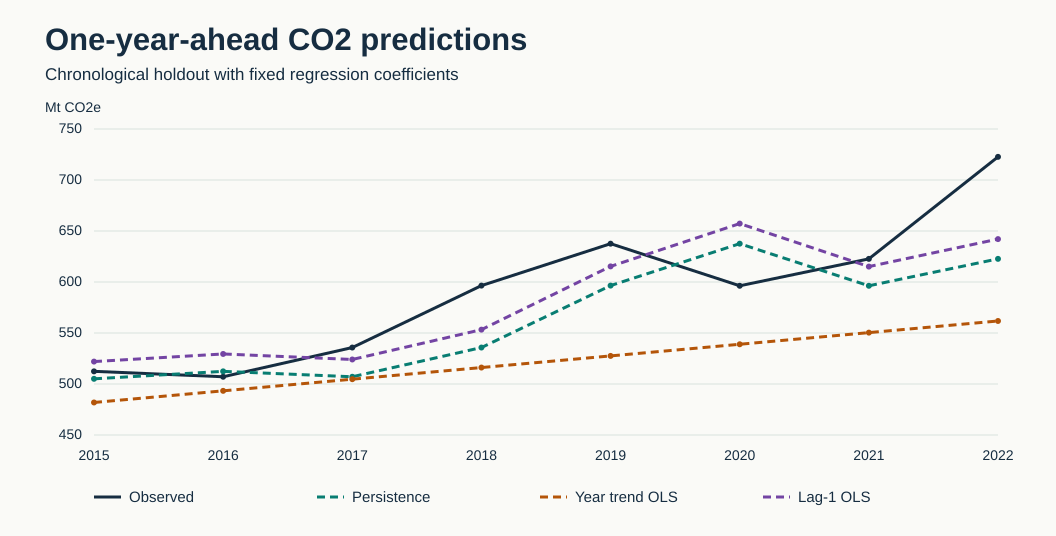

In [14]:
from IPython.display import display, SVG

display(SVG(filename="/content/indonesia-co2/outputs/national/plots/annual_emissions.svg"))
display(SVG(filename="/content/indonesia-co2/outputs/national/plots/holdout_predictions.svg"))

### Interpretation of the Graphs

Indonesia’s national CO₂ emissions increased overall between 1970 and 2022. Emissions declined in 2020, then increased in 2021 and 2022. The dashed vertical line marks the start of the holdout period in 2015.

The second graph compares observed emissions with one-year-ahead predictions. Lag-1 OLS achieved the lowest holdout RMSE of 40.87 Mt CO₂e, compared with 48.33 for persistence and 82.96 for year-trend OLS.

The year-trend model underestimated emissions throughout the holdout period. The lag-based models followed changes more closely, but struggled with sudden changes, particularly in 2020 and 2022.

These results describe national emissions only. They do not establish causes or show district-level climate and health relationships.

## 14. Display the Output Tables
Display the CSV results generated by the Go program. Python is used only to present the saved tables.

In [15]:
import pandas as pd
from IPython.display import display, Markdown

base = "/content/indonesia-co2/outputs/national/"

tables = [
    ("Cleaned Annual Data — First 10 Rows", "annual_co2_clean.csv"),
    ("Holdout Predictions", "holdout_predictions.csv"),
    ("Model Coefficients", "model_coefficients.csv"),
    ("Model Evaluation Metrics", "model_metrics.csv"),
]

for title, filename in tables:
    display(Markdown(f"### {title}"))
    table = pd.read_csv(base + filename)
    display(table.head(10) if filename == "annual_co2_clean.csv" else table)

### Cleaned Annual Data — First 10 Rows

,country_code,year,co2_mt_co2e,yoy_change_mt_co2e,yoy_change_pct
0,IDN,1970,31.1237,NaN,NaN
1,IDN,1971,31.4961,0.3724,1.1965
2,IDN,1972,37.2634,5.7673,18.3112
3,IDN,1973,42.0333,4.7699,12.8005
4,IDN,1974,46.9566,4.9233,11.7129
5,IDN,1975,48.7947,1.8381,3.9145
6,IDN,1976,52.5271,3.7324,7.6492
7,IDN,1977,71.7987,19.2716,36.6889
8,IDN,1978,84.4666,12.6679,17.6436
9,IDN,1979,90.9196,6.4530,7.6397


### Holdout Predictions

,model,year,actual_mt_co2e,predicted_mt_co2e,actual_minus_prediction_mt_co2e
0,Persistence,2015,512.3973,505.0762,7.3211
1,Persistence,2016,507.0965,512.3973,-5.3008
2,Persistence,2017,535.7474,507.0965,28.6509
3,Persistence,2018,596.4692,535.7474,60.7218
4,Persistence,2019,637.5692,596.4692,41.1000
5,Persistence,2020,596.2839,637.5692,-41.2853
6,Persistence,2021,622.6868,596.2839,26.4029
7,Persistence,2022,722.6996,622.6868,100.0128
8,Year trend OLS,2015,512.3973,481.8795,30.5178
9,Year trend OLS,2016,507.0965,493.2945,13.8020


### Model Coefficients

,model,predictor,intercept,slope
0,Persistence,prior_year_co2_mt_co2e,0.0000,1.0000
1,Year trend OLS,year_minus_1970,-31.7946,11.4150
2,Lag-1 OLS,prior_year_co2_mt_co2e,6.2540,1.0211


### Model Evaluation Metrics

,model,holdout_years,mae_mt_co2e,rmse_mt_co2e,r_squared
0,Persistence,8,38.8495,48.3258,0.4929
1,Year trend OLS,8,69.5368,82.9587,-0.4943
2,Lag-1 OLS,8,32.2846,40.8747,0.6372


## 15. Analysis Insights
The following summary was generated by the Go program from the supplied data and model results.

In [16]:
from pathlib import Path
from IPython.display import display, Markdown

insights = Path(
    "/content/indonesia-co2/outputs/national/insights.md"
).read_text(encoding="utf-8")

display(Markdown(insights))

# Indonesia’s national CO2 emissions

The supplied data contain 53 consecutive years from 1970 to 2022. The indicator (EN.GHG.CO2.MT.CE.AR5) measures national CO2 emissions excluding land use, land-use change and forestry, in Mt CO2e.

- Emissions rose from **31.1237 Mt CO2e in 1970** to **722.6996 Mt CO2e in 2022**. The net change was +691.5759 Mt CO2e.
- The largest annual increase was **+100.0128 Mt CO2e in 2022**. The smallest annual change was **-41.2853 Mt CO2e in 2020**.

## Model performance

The OLS models used 1971–2014 target years. The holdout covered 2015–2022. Lagged models use the previous observed year for each one-year-ahead prediction. Model coefficients remain fixed after training.

| Model | MAE (Mt CO2e) | RMSE (Mt CO2e) | R² |
|---|---:|---:|---:|
| Persistence | 38.85 | 48.33 | 0.493 |
| Year trend OLS | 69.54 | 82.96 | -0.494 |
| Lag-1 OLS | 32.28 | 40.87 | 0.637 |

**Lag-1 OLS** had the lowest RMSE (**40.87 Mt CO2e**) on this holdout. The fitted time trend was 11.41 Mt CO2e per year. In the lag regression, an extra 1 Mt CO2e in the previous year increases the fitted next-year value by 1.0211 Mt CO2e. These are descriptive relationships, and the scores depend on a single holdout of 8 years.

## Geographic and data coverage

The source reports one national total per year. District emissions, climate and health relationships require the lecturer’s district, coordinate, temperature, demographics and health datasets.


## 16. Conclusion and Limitations

Indonesia’s national CO₂ emissions increased overall from 1970 to 2022. Among the models evaluated, Lag-1 OLS performed best on the 2015–2022 holdout, with an MAE of 32.28 Mt CO₂e, an RMSE of 40.87 Mt CO₂e and an R² of 0.637.

Previous-year emissions were useful for one-year-ahead prediction. However, sudden annual changes remained difficult to predict. The year-trend model performed poorly, with a negative holdout R².

The evaluation uses a single eight-year holdout, so the results may differ for other periods. These predictions use the previous observed year and are not multi-year forecasts made entirely in 2014.

The supplied dataset contains national emissions only. Real spatial matching, district comparisons and climate–health analysis remain incomplete because the required additional datasets have not been supplied to this notebook. The district tests use synthetic data and do not demonstrate real district findings.

## 17. Download the Project
Download the Go source files, input dataset and generated outputs as a ZIP archive.

In [ ]:
import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/Indonesia_CO2_Project",
    "zip",
    root_dir="/content/indonesia-co2"
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Confirmed Project Scope
The lecturer confirmed that this project should focus on predicting national CO₂ emissions from historical data using a simple regression model in Go. Spatial matching and district-level analysis are outside the confirmed scope.

Generative AI use is documented through prompts, explanations and validation steps used while learning and applying Go.